Comparative Clustering Analysis: Partitional (K-Means) vs. Hierarchical (Agglomerative)
Customer Segmentation and Unsupervised Validation Frameworks on the Mall Customer Dataset

# Step 1: Import Libraries and Load Dataset Simulation

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
import scipy.cluster.hierarchy as sch
np.random.seed(42)
n_samples = 200
mall_data = {
'CustomerID': range(1, n_samples + 1),
'Age': np.random.randint(18, 70, n_samples),
'Annual_Income_k': np.random.randint(15, 135, n_samples),
'Spending_Score': np.random.randint(1, 100, n_samples)
}
df = pd.DataFrame(mall_data)
print("Dataset Overview:\n", df.head())

Dataset Overview:
    CustomerID  Age  Annual_Income_k  Spending_Score
0           1   56               84              49
1           2   69               86              17
2           3   46               41              44
3           4   32               23              92
4           5   60               76              30


# Step 2 & 3: Isolate Features and Apply Preprocessing (Scaling)

In [5]:
X = df[['Annual_Income_k', 'Spending_Score']].values
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Step 4: Partitional Clustering Optimization (K-Means & Elbow Method)

In [6]:
wcss = []
k_values = range(2, 11)
for k in k_values:
    km = KMeans(n_clusters=k, init='k-means++', random_state=42, n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)
# Fit final optimal K-Means model (K=5 based on standard elbow inflection)
optimal_km = KMeans(n_clusters=5, init='k-means++', random_state=42, n_init=10)
kmeans_labels = optimal_km.fit_predict(X_scaled)
kmeans_sil = silhouette_score(X_scaled, kmeans_labels)

# Step 5: Hierarchical Agglomerative Clustering

In [7]:
optimal_agg = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='ward')
agg_labels = optimal_agg.fit_predict(X_scaled)
agg_sil = silhouette_score(X_scaled, agg_labels)

# Step 6 & 7: Print Metrics & Compare Profiles

In [8]:
print(f'\nK-Means (K=5) WCSS (Inertia): {optimal_km.inertia_:.2f}')
print(f'K-Means (K=5) Silhouette Score: {kmeans_sil:.4f}')
print(f'Agglomerative (K=5) Silhouette Score: {agg_sil:.4f}')


K-Means (K=5) WCSS (Inertia): 81.74
K-Means (K=5) Silhouette Score: 0.3971
Agglomerative (K=5) Silhouette Score: 0.3373


## 5. Segment Visualizations
Let's compare the resulting clusters visually side-by-side.

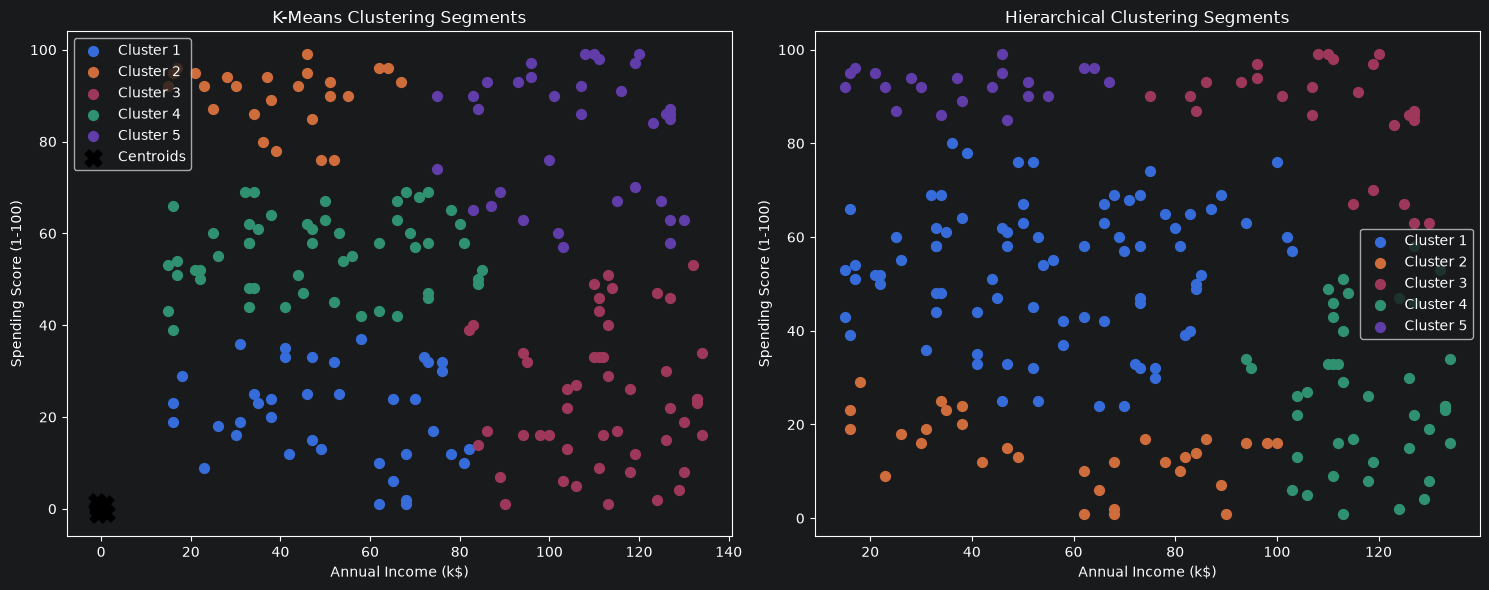

In [9]:
plt.figure(figsize=(15, 6))
OPTIMAL_K = 5
# K-Means Plot
plt.subplot(1, 2, 1)
for i in range(OPTIMAL_K):
    plt.scatter(X[kmeans_labels == i, 0], X[kmeans_labels == i, 1], s=50, label=f'Cluster {i+1}')
plt.scatter(optimal_km.cluster_centers_[:, 0], optimal_km.cluster_centers_[:, 1], s=150, c='black', marker='X', label='Centroids')
plt.title('K-Means Clustering Segments')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()

# Hierarchical Plot
plt.subplot(1, 2, 2)
for i in range(OPTIMAL_K):
    plt.scatter(X[agg_labels == i, 0], X[agg_labels == i, 1], s=50, label=f'Cluster {i+1}')
plt.title('Hierarchical Clustering Segments')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()

plt.tight_layout()
plt.show()